# A02-KM — K-Means trên RFM (Standard, không PCA)

Thí nghiệm **A02-KM** (người chạy: Nguyên) theo chiến lược model. So với A01, **chỉ bỏ PCA**: làm sạch → RFM → StandardScaler → K-Means (không PCA). Mục đích: đo tác động của PCA lên kết quả phân cụm.

Dữ liệu, seed và quy tắc chọn k giữ nguyên như A01-KM / A03-KM để ba thí nghiệm so sánh được với nhau.

## Params

In [1]:
FEATURES = ["Recency", "Frequency", "Monetary"]
K_GRID = range(2, 11)         # quét k = 2..10 (giống A03-KM)
RANDOM_STATE = 42
N_INIT = 20                   # giống A03-KM; A01-KM dùng 10 (kiểm ở k=2: cùng Silhouette và Inertia)
PCA_VARIANCE_A01 = 0.90       # ngưỡng PCA của A01 — chỉ để đối chiếu, A02 không dùng PCA
PCA_COMPONENTS_A03 = 2        # PCA cố định của A03 — chỉ để đối chiếu

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

# Dùng chung file đặc trưng của nhóm (cùng nguồn với A01-KM, A01-DB, A03-KM), không sao chép thêm
REL = "notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv"
DATA = next(c for p in [Path.cwd(), *Path.cwd().parents]
            for c in (p / REL, p / "project" / REL) if c.exists())
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"})
X = df[FEATURES].copy()
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 3)


,Recency,Frequency,Monetary
count,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95
std,99.98,7.64,8441.89
min,1.00,1.00,2.90
25%,18.00,1.00,301.52
50%,51.00,2.00,657.90
75%,143.00,5.00,1624.10
max,374.00,206.00,278748.02


**Nhận xét:** 4.327 khách, mỗi dòng một khách (CustomerID không trùng), không thiếu giá trị. Phân phối lệch phải rất mạnh: Monetary có median 657,9 nhưng max 278.748; Frequency median 2, max 206. Đây là dữ liệu K-Means sẽ phải chịu ở bước sau.

**Lưu ý nguồn dữ liệu:** file dùng chung này là kết quả làm sạch cũ của nhóm, không phải RFM tính thẳng từ raw. So với RFM tính từ raw theo quy tắc giữ-dòng của FS1 (4.338 khách, `05_data_processing/12-11-2026-Nguyen-tien-xu-ly-fs1`): thiếu 11 khách; Monetary thấp hơn ở 1.421 khách và Frequency thấp hơn ở 113 khách, không khách nào cao hơn (ví dụ khách 16446: 2,9 so với 168.472,5). Kết quả A02/A01/A03 so sánh được với nhau vì cùng một file, nhưng chưa phải số liệu từ raw.

## Chuẩn hóa (không PCA)

In [3]:
scaler = StandardScaler().fit(X)
X_scaled = scaler.transform(X)

# Chẩn đoán PCA — KHÔNG dùng làm đầu vào, chỉ để biết PCA 90%/95% của A01/A04 có bỏ chiều nào không
cum = np.cumsum(PCA(svd_solver="full").fit(X_scaled).explained_variance_ratio_)
n90 = int(np.searchsorted(cum, 0.90) + 1)
n95 = int(np.searchsorted(cum, 0.95) + 1)
print("Phương sai tích lũy theo số PC:", cum.round(4))
print(f"Số PC cần cho 90%: {n90} | cho 95%: {n95} | tổng số biến: {len(FEATURES)}")

Phương sai tích lũy theo số PC: [0.5638 0.8655 1.    ]
Số PC cần cho 90%: 3 | cho 95%: 3 | tổng số biến: 3


**Nhận xét:** 2 PC mới giữ 86,55% phương sai; phải đủ cả 3 PC mới vượt 90% (và 95%). Nghĩa là PCA 90% của A01 **không bỏ chiều nào**, chỉ xoay trục. K-Means dùng khoảng cách Euclid, không đổi khi xoay trục, nên về lý thuyết bỏ PCA (A02) cho cùng kết quả với A01. Các bước sau kiểm lại điều này bằng số.

## Quét số cụm k

Chọn k theo **Silhouette lớn nhất** — cùng quy tắc A01-KM và A03-KM. Mọi chỉ số tính trên `X_scaled` (đúng không gian mô hình được fit). Thêm cột `min_cluster` (số khách của cụm nhỏ nhất) để thấy k lớn có làm vỡ cụm không.

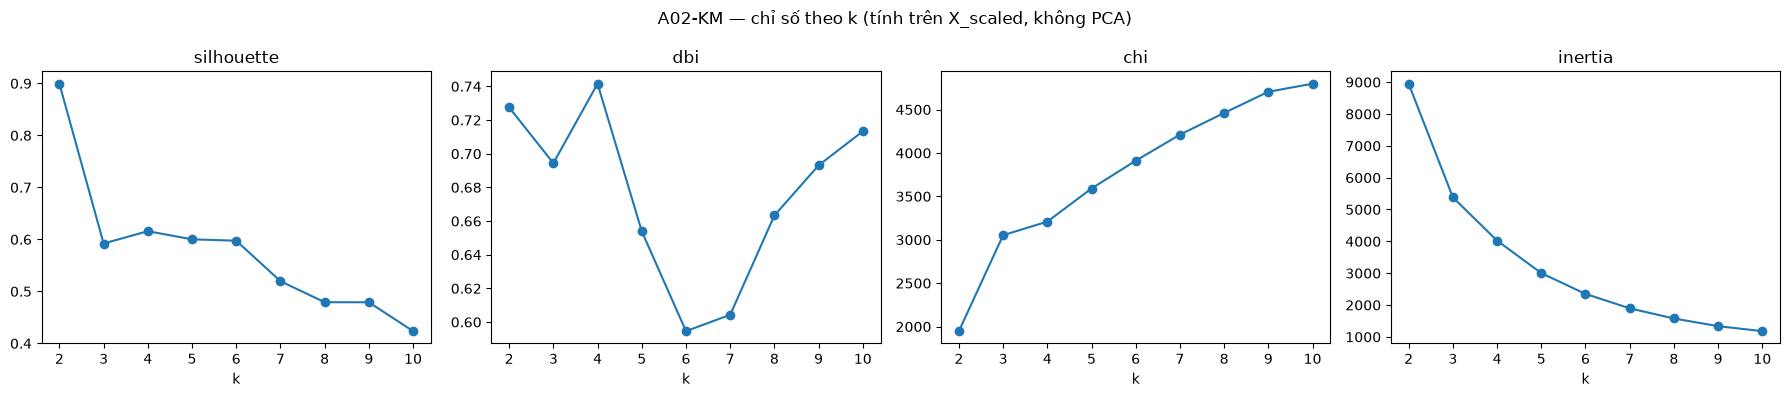

,k,silhouette,dbi,chi,inertia,min_cluster
0,2,0.8994,0.7275,1947.5,8950.6,24
1,3,0.5921,0.6944,3052.7,5381.8,24
2,4,0.6158,0.7416,3209.0,4022.7,12
3,5,0.6001,0.6539,3590.6,3002.7,3
4,6,0.5975,0.5946,3911.1,2349.2,2
5,7,0.5196,0.6043,4210.6,1895.6,2
6,8,0.4792,0.6633,4461.3,1577.2,2
7,9,0.4791,0.6931,4705.2,1335.8,2
8,10,0.4236,0.7133,4797.9,1179.8,2


In [4]:
rows, labels_by_k = [], {}
for k in K_GRID:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit(X_scaled)
    labels_by_k[k] = km.labels_
    rows.append({"k": k,
                 "silhouette": round(silhouette_score(X_scaled, km.labels_), 4),
                 "dbi": round(davies_bouldin_score(X_scaled, km.labels_), 4),
                 "chi": round(calinski_harabasz_score(X_scaled, km.labels_), 1),
                 "inertia": round(km.inertia_, 1),
                 "min_cluster": int(np.bincount(km.labels_).min())})
metrics = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["silhouette", "dbi", "chi", "inertia"]):
    ax.plot(metrics["k"], metrics[col], marker="o")
    ax.set_xlabel("k"); ax.set_title(col)
plt.suptitle("A02-KM — chỉ số theo k (tính trên X_scaled, không PCA)")
plt.tight_layout()
plt.savefig(FIG / "kmeans_metrics.png", dpi=150)
plt.show()
metrics

**Nhận xét:** Silhouette cao nhất ở k=2 (0,8994), rồi tụt còn khoảng 0,59–0,62 ở k=3–6. Từ k=5 đã có cụm chỉ 3 khách, từ k=6 trở đi có cụm chỉ 2 khách: K-Means trên RFM thô tách thêm từng điểm ngoại lai chứ không chia thêm phân khúc. CHI tăng đều theo k nên không dùng một mình để chọn k; DBI dao động 0,59–0,74, không có điểm gãy rõ.

## Chọn k và huấn luyện mô hình cuối

In [5]:
best_k = int(metrics.loc[metrics["silhouette"].idxmax(), "k"])
print("k được chọn (Silhouette lớn nhất):", best_k)

model = Pipeline([("scaler", StandardScaler()),
                  ("kmeans", KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=N_INIT))]).fit(X)
labels = model["kmeans"].labels_
assert (labels == labels_by_k[best_k]).all()      # pipeline cho đúng nhãn đã quét ở trên
print(pd.Series(labels).value_counts().sort_index().rename("Số khách"))

k được chọn (Silhouette lớn nhất): 2
0    4303
1      24
Name: Số khách, dtype: int64


**Nhận xét:** k=2 chia 4.303 khách vào cụm 0 và chỉ 24 khách (0,55%) vào cụm 1 — lệch gần tuyệt đối, đây là việc tách một nhóm ngoại lai chứ chưa phải phân khúc cân đối.

## Đối chiếu A01 và A03 (dựng lại cùng điều kiện)

Không chép số từ file khác: dựng lại A01 (StandardScaler → PCA 90% → K-Means) và A03 (PCA cố định 2 PC) ngay tại đây, cùng seed và `n_init`. ARI (Adjusted Rand Index) đo mức trùng nhóm giữa hai kết quả; 1,0 là hai cách chia giống hệt nhau.

In [6]:
Z_a01 = PCA(n_components=PCA_VARIANCE_A01, svd_solver="full").fit_transform(X_scaled)
Z_a03 = PCA(n_components=PCA_COMPONENTS_A03, svd_solver="full").fit_transform(X_scaled)
print(f"Số PC giữ lại: A01 = {Z_a01.shape[1]} | A03 = {Z_a03.shape[1]}")

# A02 so với A01 ở mọi k
rows = []
for k in K_GRID:
    km01 = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z_a01)
    m = metrics.loc[metrics.k == k].iloc[0]
    rows.append({"k": k,
                 "ARI_A02_vs_A01": round(adjusted_rand_score(labels_by_k[k], km01.labels_), 4),
                 "silhouette_A02": m["silhouette"],
                 "silhouette_A01": round(silhouette_score(Z_a01, km01.labels_), 4),
                 "inertia_A02": m["inertia"],
                 "inertia_A01": round(km01.inertia_, 1)})
cmp_k = pd.DataFrame(rows)
print(cmp_k.to_string(index=False))

Số PC giữ lại: A01 = 3 | A03 = 2


 k  ARI_A02_vs_A01  silhouette_A02  silhouette_A01  inertia_A02  inertia_A01
 2             1.0          0.8994          0.8994       8950.6       8950.6
 3             1.0          0.5921          0.5921       5381.8       5381.8
 4             1.0          0.6158          0.6158       4022.7       4022.7
 5             1.0          0.6001          0.6001       3002.7       3002.7
 6             1.0          0.5975          0.5975       2349.2       2349.2
 7             1.0          0.5196          0.5196       1895.6       1895.6
 8             1.0          0.4792          0.4792       1577.2       1577.2
 9             1.0          0.4791          0.4791       1335.8       1335.8
10             1.0          0.4236          0.4236       1179.8       1179.8


In [7]:
# Ba thí nghiệm tại k được chọn
def score(Z, km, ref_labels):
    return {"k": best_k,
            "Silhouette": round(silhouette_score(Z, km.labels_), 4),
            "DBI": round(davies_bouldin_score(Z, km.labels_), 4),
            "CHI": round(calinski_harabasz_score(Z, km.labels_), 1),
            "Inertia": round(km.inertia_, 1),
            "ARI so với A02": round(adjusted_rand_score(ref_labels, km.labels_), 4)}

km01 = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z_a01)
km03 = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z_a03)
cmp = pd.DataFrame([
    {"Thí nghiệm": "A02-KM", "Cấu hình": "Standard, không PCA", **score(X_scaled, model["kmeans"], labels)},
    {"Thí nghiệm": "A01-KM (dựng lại)", "Cấu hình": "Standard + PCA 90%", **score(Z_a01, km01, labels)},
    {"Thí nghiệm": "A03-KM (dựng lại)", "Cấu hình": "Standard + PCA 2 PC", **score(Z_a03, km03, labels)},
])
cmp

,Thí nghiệm,Cấu hình,k,Silhouette,DBI,CHI,Inertia,ARI so với A02
0,A02-KM,"Standard, không PCA",2,0.8994,0.7275,1947.5,8950.6,1.0
1,A01-KM (dựng lại),Standard + PCA 90%,2,0.8994,0.7275,1947.5,8950.6,1.0
2,A03-KM (dựng lại),Standard + PCA 2 PC,2,0.8952,0.5119,2418.6,7205.2,1.0


**Nhận xét:** **A02 trùng hoàn toàn A01**: PCA 90% giữ cả 3 PC nên ARI = 1,0 ở mọi k từ 2 đến 10, và Silhouette, Inertia giống nhau đến 4 chữ số. Theo bảng chiến lược, trường hợp này ghi là *tương đương A01*; PCA 90% không có tác dụng trên RFM 3 biến. A03 ở k=2 cho **cùng cách chia** (ARI = 1,0) nhưng chỉ số khác (Silhouette 0,8952, DBI 0,5119) vì tính trên không gian 2 PC — chỉ số của các không gian khác nhau không so trực tiếp được.

In [8]:
# Kiểm số liệu A01-KM trong Working_details của Hiếu: Silhouette 0,9698 | DBI 0,6607 | CHI 4439,57
print("Tính trên X chưa chuẩn hóa:",
      round(silhouette_score(X, labels), 4), round(davies_bouldin_score(X, labels), 4),
      round(calinski_harabasz_score(X, labels), 2))
print("Tính trên X_scaled        :",
      round(silhouette_score(X_scaled, labels), 4), round(davies_bouldin_score(X_scaled, labels), 4),
      round(calinski_harabasz_score(X_scaled, labels), 2))

Tính trên X chưa chuẩn hóa: 0.9698 0.6607 4439.57


Tính trên X_scaled        : 0.8994 0.7275 1947.52


**Nhận xét:** Ba số 0,9698 / 0,6607 / 4439,57 trong `Working_details` của A01-KM khớp đúng với việc tính **trên X chưa chuẩn hóa** (file đó cũng ghi dấu * "cần tính lại trên X_scaled"). Số đúng trên X_scaled là 0,8994 / 0,7275 / 1947,5 — cũng chính là giá trị A01 mà A03-KM của An đã dẫn. Khi so sánh các thí nghiệm, dùng số đã tính lại này.

## Hồ sơ cụm

In [9]:
prof = X.assign(cluster=labels).groupby("cluster").agg(
    customers=("Monetary", "size"),
    Recency=("Recency", "median"),
    Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"),
    Monetary_sum=("Monetary", "sum"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof = prof.drop(columns="Monetary_sum")
prof.round(1)

,customers,Recency,Frequency,Monetary,customer_share_pct,Monetary_share_pct
cluster,,,,,,
0,4303,52.0,2.0,655.6,99.4,76.5
1,24,3.5,55.5,58396.3,0.6,23.5


**Nhận xét:** Cụm 1 (24 khách, 0,55%) có Recency median 3,5 ngày, Frequency 55,5, Monetary median 58.396 và chiếm 23,5% tổng Monetary; cụm 0 (4.303 khách) có Frequency 2, Monetary 655,6. Giống A01/A03: Silhouette lớn nhất chỉ tách nhóm khách ngoại lai. Gốc vấn đề là phân phối lệch phải của RFM thô chứ không phải PCA.

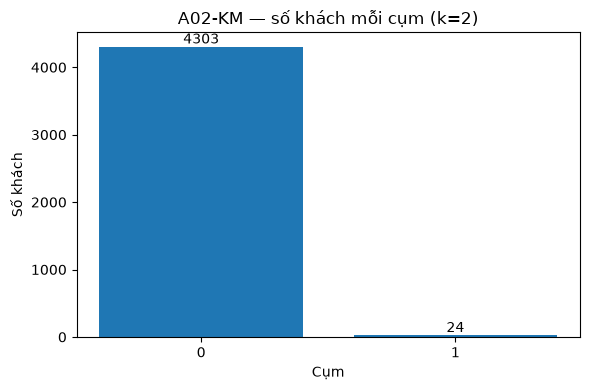

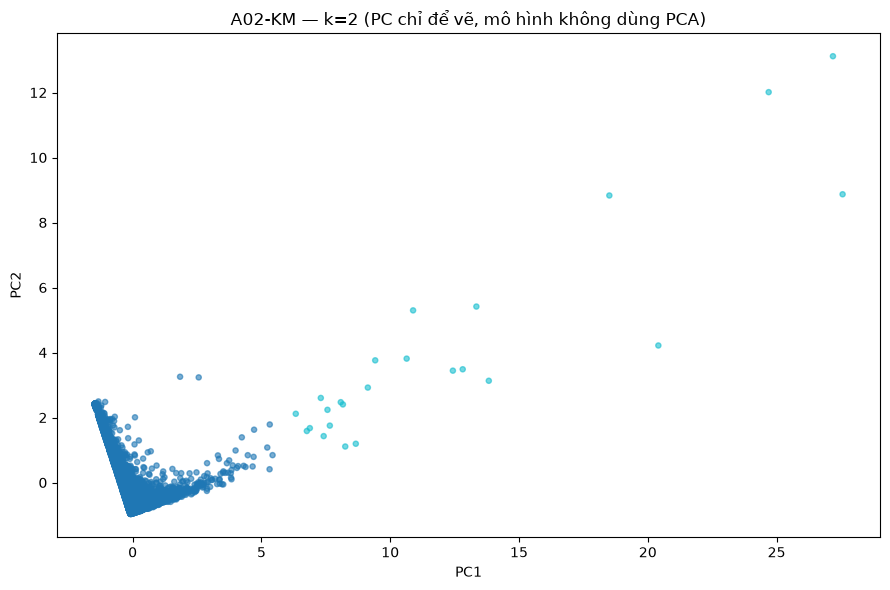

In [10]:
# Hình 1: số khách mỗi cụm
sizes = pd.Series(labels).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(sizes.index.astype(str), sizes.values)
ax.bar_label(bars)
ax.set_xlabel("Cụm"); ax.set_ylabel("Số khách"); ax.set_title(f"A02-KM — số khách mỗi cụm (k={best_k})")
plt.tight_layout(); plt.savefig(FIG / "kmeans_cluster_distribution.png", dpi=150); plt.show()

# Hình 2: chiếu 2 PC chỉ để VẼ (mô hình không dùng PCA)
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(Z_a03[:, 0], Z_a03[:, 1], c=labels, cmap="tab10", s=14, alpha=0.6)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"A02-KM — k={best_k} (PC chỉ để vẽ, mô hình không dùng PCA)")
plt.tight_layout(); plt.savefig(FIG / "kmeans_clusters_pca.png", dpi=150); plt.show()

**Nhận xét:** Hình cho thấy một khối khách lớn dồn gần gốc tọa độ và vài điểm xa kéo dài theo PC1 — đó chính là 24 khách của cụm 1.

## Lưu kết quả

In [11]:
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "kmeans_a02_labels.csv", index=False)
joblib.dump(model, "kmeans_model.pkl")

m = metrics.loc[metrics.k == best_k].iloc[0]
params = {"experiment": "A02-KM", "features": FEATURES, "scaler": "StandardScaler", "pca": None,
          "k": best_k, "n_customers": int(len(X)),
          "silhouette": float(m["silhouette"]), "dbi": float(m["dbi"]),
          "chi": float(m["chi"]), "inertia": float(m["inertia"]),
          "equivalent_to": "A01-KM (PCA 90% giữ đủ 3 PC, ARI = 1.0)",
          "kmeans_params": model["kmeans"].get_params()}
json.dump(params, open("kmeans_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in Path(".").iterdir() if p.is_file()), sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['Working_details_KMeans_A02.xlsx', 'kmeans_a02.ipynb', 'kmeans_model.pkl', 'kmeans_params.json'] ['kmeans_a02_labels.csv']


## Working_details

Ghi bảng tóm tắt theo đúng bố cục `Working_details_KMeans_RFM.xlsx` của A01-KM (thiết lập, bảng theo k, bảng cụm), thêm một bảng đối chiếu A01/A03 và sửa tiêu đề cột "Cụm" bị lặp ở file mẫu.

In [12]:
from openpyxl import Workbook
from openpyxl.styles import Font

wb = Workbook(); ws = wb.active; ws.title = "KMeans_A02"
B = Font(name="Calibri", bold=True)
def put(cell, value, bold=False, fmt=None):
    ws[cell] = value
    ws[cell].font = B if bold else Font(name="Calibri")
    if fmt: ws[cell].number_format = fmt

put("A1", "THÍ NGHIỆM K-MEANS — A02 (RFM, Standard, KHÔNG PCA)", bold=True)
put("A2", "Trạng thái", bold=True)
put("B2", "Đã chạy xong; chỉ số tính trên X_scaled. Kết luận: tương đương A01 (ARI = 1,0)")

for c, v in zip("ABDE", ["Thiết lập", "Giá trị", "Tham số khác", "Giá trị"]): put(f"{c}4", v, bold=True)
left = [("Feature", "Recency, Frequency, Monetary"), ("Dữ liệu train", "X_scaled (StandardScaler)"),
        ("K được chọn", best_k), ("random_state", RANDOM_STATE), ("init", "k-means++"), ("n_init", N_INIT)]
right = [("max_iter", 300), ("tol", 0.0001), ("Tổng khách hàng", int(len(X))), ("Số cụm", best_k),
         ("PCA", "Không (A01: 90% = 3 PC)"), ("Nguồn dữ liệu", "12-11-2026-hieu-kmeans/data/customer_features.csv")]
for i, ((a, b), (d, e)) in enumerate(zip(left, right), start=5):
    put(f"A{i}", a); put(f"B{i}", b); put(f"D{i}", d); put(f"E{i}", e)
ws["E6"].number_format = "0.0000"

for c, v in zip("ABCDEF", ["k", "Silhouette", "DBI", "CHI", "Inertia", "Nhận xét"]): put(f"{c}12", v, bold=True)
for i, r in enumerate(metrics.itertuples(), start=13):
    put(f"A{i}", int(r.k)); put(f"B{i}", r.silhouette, fmt="0.0000"); put(f"C{i}", r.dbi, fmt="0.0000")
    put(f"D{i}", r.chi, fmt="0.00"); put(f"E{i}", r.inertia, fmt="0.00")
    note = "k được chọn (Silhouette lớn nhất)" if r.k == best_k else ""
    if r.min_cluster <= 5: note = (note + "; " if note else "") + f"cụm nhỏ nhất chỉ {r.min_cluster} khách"
    put(f"F{i}", note)

hdr = ["Cụm", "Nhóm khách hàng", "Số khách", "Tỷ lệ (%)", "Recency (median)", "Frequency (median)",
       "Monetary (median)", "Tỷ trọng Monetary (%)"]
r0 = 13 + len(metrics) + 2                       # chừa 2 dòng trống sau bảng k
for c, v in zip("ABCDEFGH", hdr): put(f"{c}{r0}", v, bold=True)
for j, (cl, p) in enumerate(prof.iterrows(), start=r0 + 1):
    nhom = ("Monetary cao nhất" if p["Monetary"] == prof["Monetary"].max()
            else "Monetary thấp nhất" if p["Monetary"] == prof["Monetary"].min() else "Trung gian")
    put(f"A{j}", int(cl)); put(f"B{j}", nhom); put(f"C{j}", int(p["customers"]))
    put(f"D{j}", float(p["customer_share_pct"]), fmt="0.00"); put(f"E{j}", float(p["Recency"]))
    put(f"F{j}", float(p["Frequency"])); put(f"G{j}", float(p["Monetary"]), fmt="0.00")
    put(f"H{j}", float(p["Monetary_share_pct"]), fmt="0.00")

r1 = r0 + len(prof) + 3
put(f"A{r1}", f"Đối chiếu tại k = {best_k} (chỉ số tính trên không gian đã fit của từng thí nghiệm)", bold=True)
cols = ["Thí nghiệm", "Cấu hình", "k", "Silhouette", "DBI", "CHI", "Inertia", "ARI so với A02"]
for c, v in zip("ABCDEFGH", cols): put(f"{c}{r1+1}", v, bold=True)
for j, r in enumerate(cmp.itertuples(index=False), start=r1 + 2):
    vals = list(r)
    for c, v in zip("ABCDEFGH", vals):
        put(f"{c}{j}", v if not isinstance(v, (np.integer, np.floating)) else v.item(),
            fmt="0.0000" if c in "DEH" else ("0.00" if c in "FG" else None))
put(f"A{r1+6}", "A03 tính trên không gian 2 PC nên Silhouette/DBI/CHI/Inertia không so trực tiếp với A01/A02.")

for col, w in zip("ABCDEFGHI", [16, 22, 17, 19, 20, 21, 25, 22, 13]): ws.column_dimensions[col].width = w
ws.freeze_panes = "A5"
wb.save("Working_details_KMeans_A02.xlsx")
print("Đã lưu Working_details_KMeans_A02.xlsx")

Đã lưu Working_details_KMeans_A02.xlsx


## Kết luận A02-KM

- **A02 ≡ A01.** Với 3 biến RFM, PCA 90% (và 95%) giữ đủ 3 PC nên chỉ xoay trục; K-Means cho ARI = 1,0 ở mọi k = 2–10. Bỏ PCA không đổi gì — ghi *tương đương A01*, không cần chạy lại các biến thể PCA ngưỡng cao.
- **k=2 theo Silhouette** vẫn chỉ tách 24 khách ngoại lai (0,55%) khỏi 4.303 khách còn lại; k lớn hơn làm vỡ thành cụm 2–3 khách.
- **Nút thắt là phân phối lệch phải của RFM thô**, không phải PCA. Hướng kiểm chứng tiếp theo là nhánh B (log1p trước khi scale).